# Lectura de los datos

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

df = pd.read_csv('data/digit/train.csv')

In [3]:
print("El conjunto de datos tiene {} filas y {} columnas".format(df.shape[0],df.shape[1]))
df.head(10)

El conjunto de datos tiene 42000 filas y 785 columnas


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
8,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
y = df.label.values
x = df.drop("label",axis=1)

In [5]:
x = x.values
x = x / 255.0
print(x)

[[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


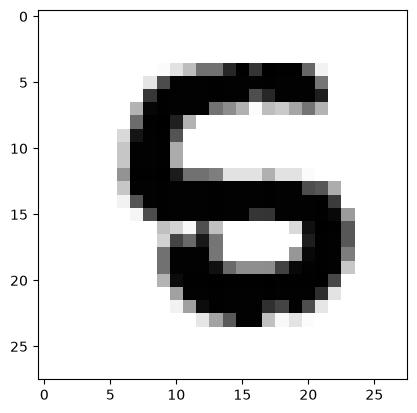

In [6]:
number = x[19].reshape(28,28)
plt.imshow(number, cmap=plt.cm.binary)
plt.show()

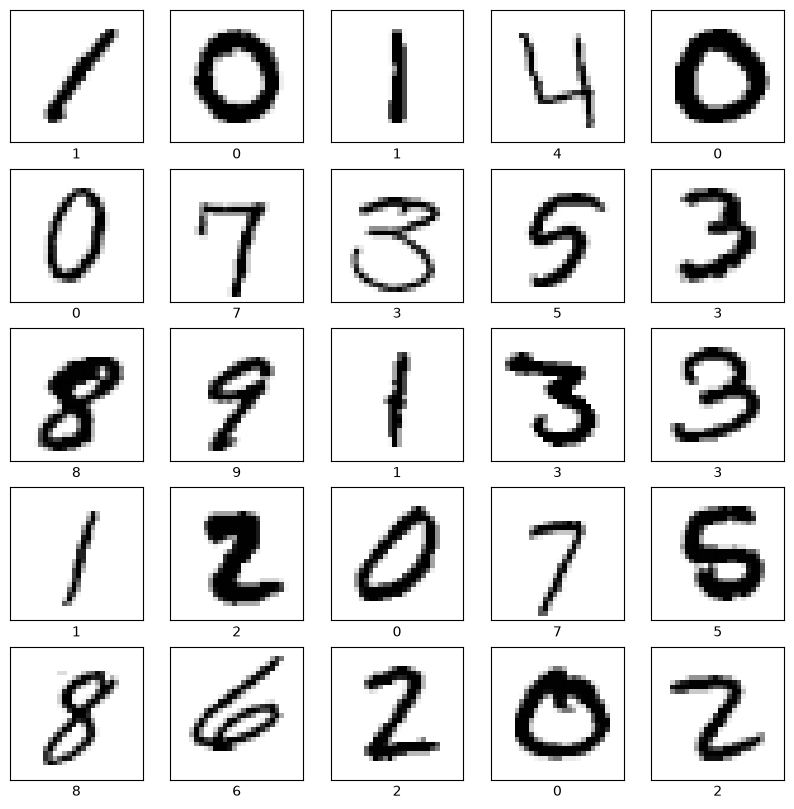

In [7]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    number = x[i].reshape(28,28)
    plt.imshow(number, cmap=plt.cm.binary)
    plt.xlabel(y[i])
plt.show()

In [8]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.30, random_state=103)

# Construyendo y entrenando la NN

In [12]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.optimizers import SGD

model = keras.Sequential([
    keras.layers.Dense(16, activation='sigmoid',input_shape=(784,)),
    keras.layers.Dense(16, activation='sigmoid'),
    keras.layers.Dense(10, activation='softmax')
])

sgd = SGD(learning_rate=0.1)
model.compile(optimizer = sgd, loss = 'sparse_categorical_crossentropy')
model.fit(x_train, y_train, epochs = 100, batch_size = 50)

Epoch 1/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.9910
Epoch 2/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.1135
Epoch 3/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6887
Epoch 4/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5193
Epoch 5/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4357
Epoch 6/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3852
Epoch 7/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3499
Epoch 8/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3228
Epoch 9/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3009
Epoch 10/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2827
Epoch 11/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2671
Epoch 12/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2536
Epoch 13/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2419
Epoch 14/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2316
Epoch 15/100
588/588 ━━━━━━━━━━━━━━━━━━━━ 1

In [13]:
test_loss = model.evaluate(x_test, y_test)

print('Test accuracy:', test_loss)

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1992
Test accuracy: 0.19920434057712555


# Probando la NN

In [14]:
predictions = model.predict(x_test)

394/394 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [15]:
predictions[0]

array([9.5247809e-04, 4.8653482e-07, 6.0211187e-05, 6.0163886e-05,
       1.8177438e-03, 5.5188709e-04, 1.0126703e-07, 8.5145664e-01,
       1.1926559e-06, 1.4509909e-01], dtype=float32)

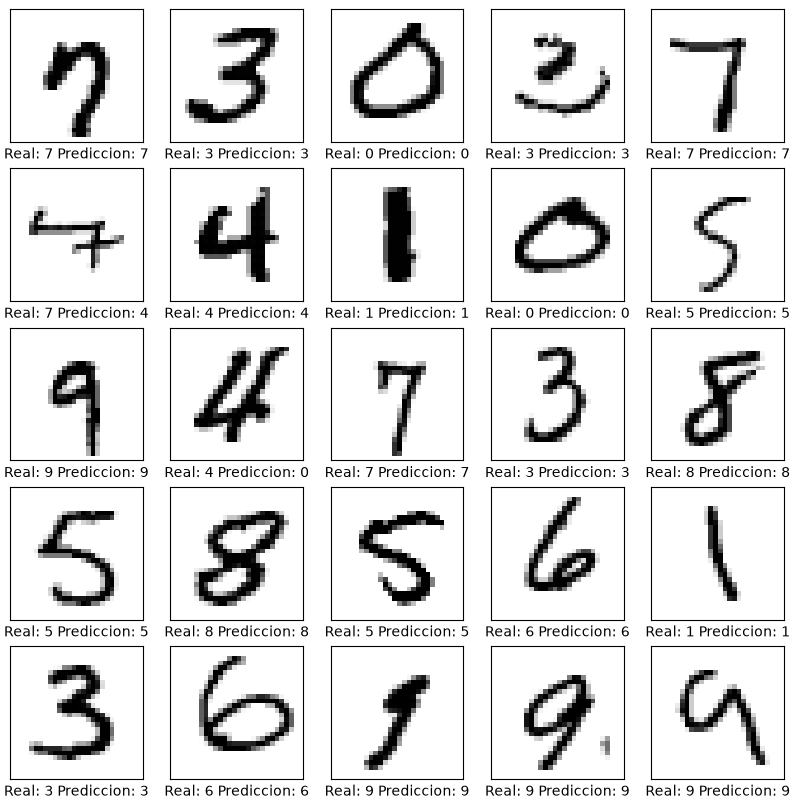

In [16]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    number = x_test[i].reshape(28,28)
    plt.imshow(number, cmap=plt.cm.binary)
    plt.xlabel("Real: {} Prediccion: {}".format
               (y_test[i],np.argmax(predictions[i])))
plt.show()

In [17]:
y_hat = np.argmax(predictions,axis=1)
y_hat[:5]

array([7, 3, 0, 3, 7])

In [18]:
y_test[:5]

array([7, 3, 0, 3, 7])

In [19]:
y_test != y_hat

array([False, False, False, ..., False, False, False], shape=(12600,))

In [20]:
print("Elementos de prueba: {}".format(y_test.shape[0]))
print("Errores identificados: {}".format((y_test != y_hat).sum()))
porcentaje_error = ((y_test != y_hat).sum() * 100) / y_test.shape[0]
print("Porcentaje de error: {} %".format(porcentaje_error))

Elementos de prueba: 12600
Errores identificados: 682
Porcentaje de error: 5.412698412698413 %


In [21]:
errores = x_test[y_test != y_hat]
real_labels = y_test[y_test != y_hat]
predicted_labels = y_hat[y_test != y_hat]
errores

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(682, 784))

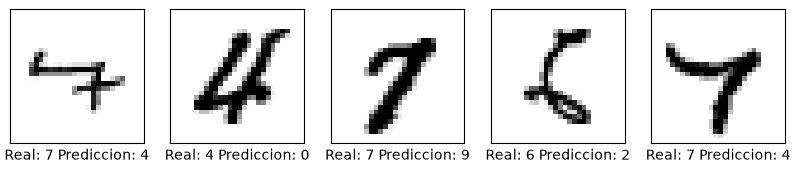

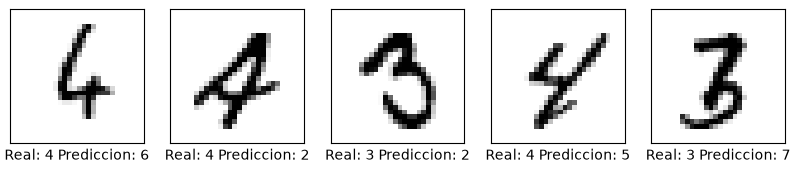

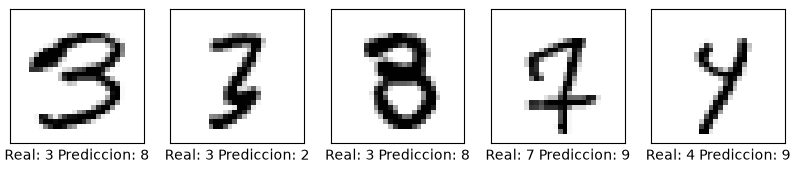

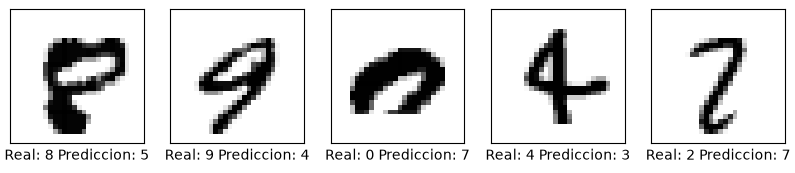

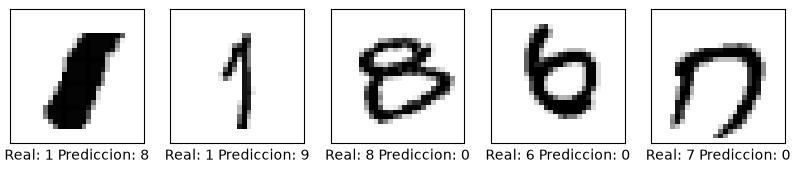

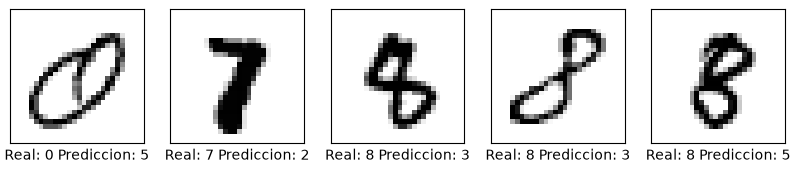

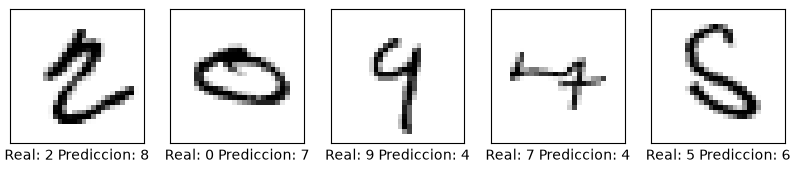

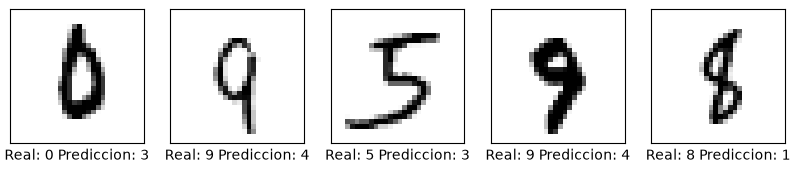

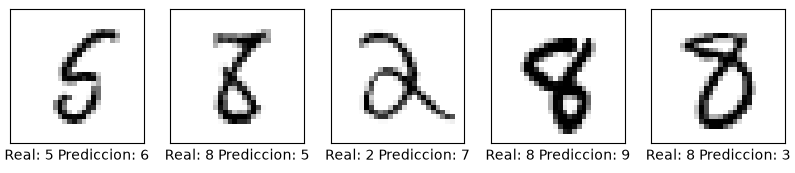

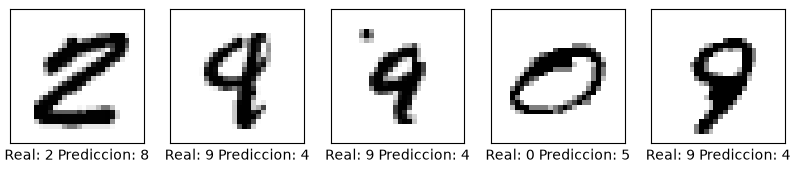

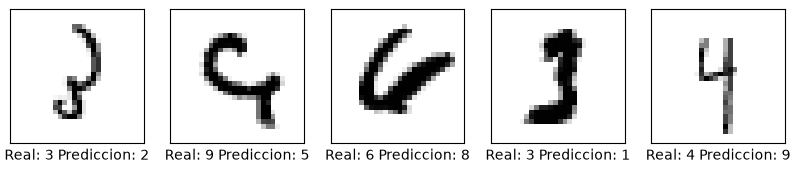

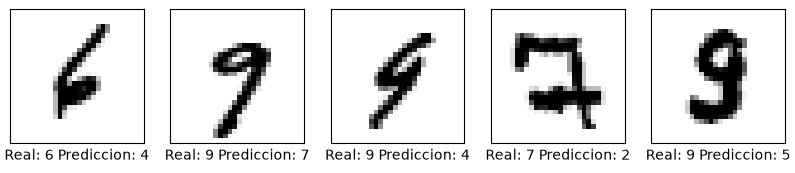

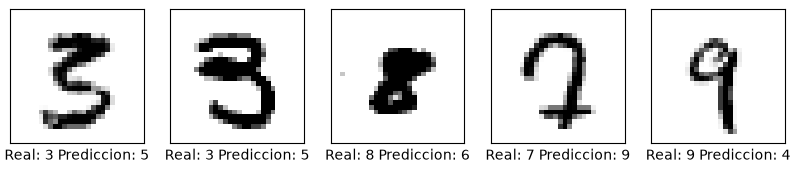

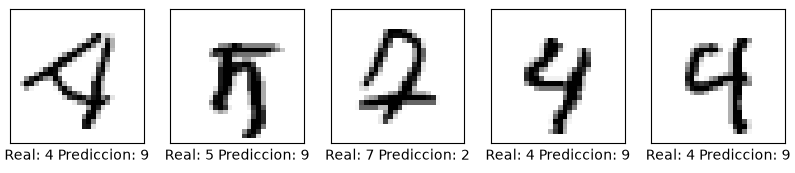

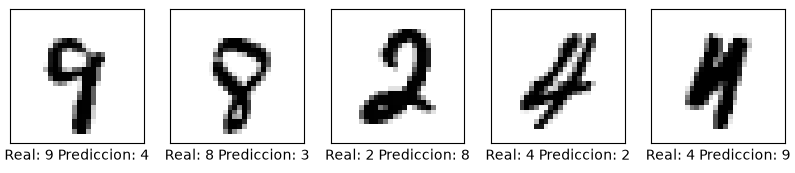

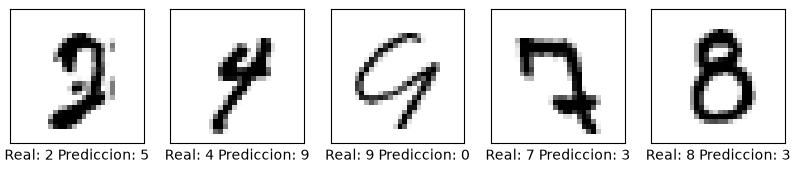

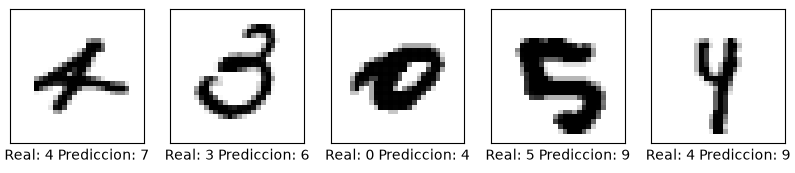

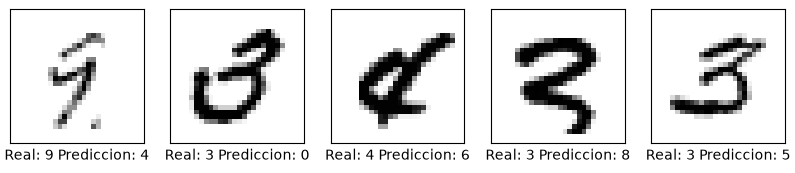

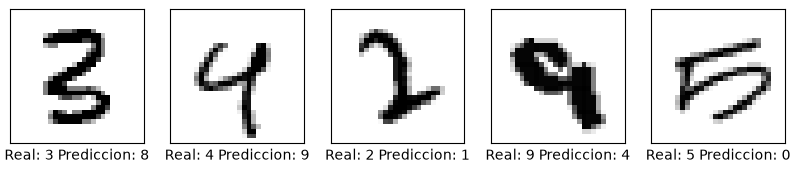

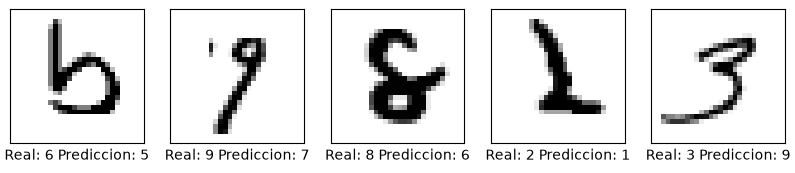

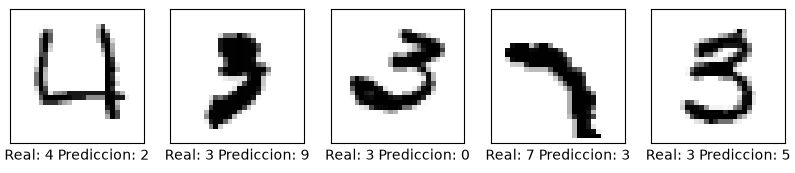

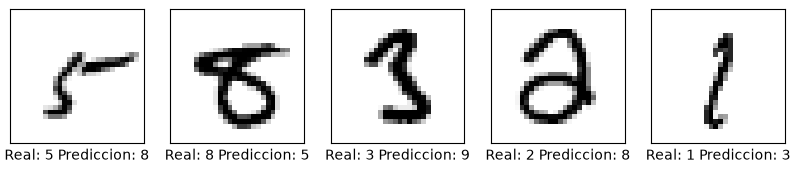

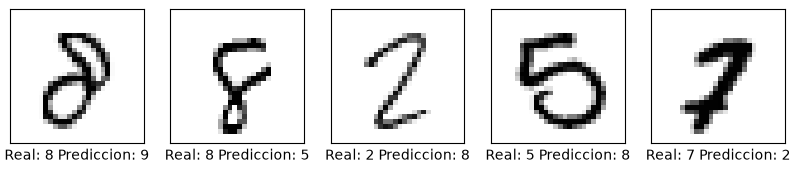

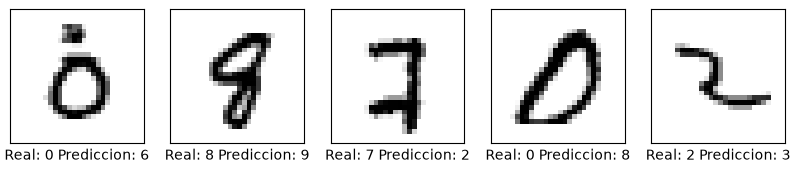

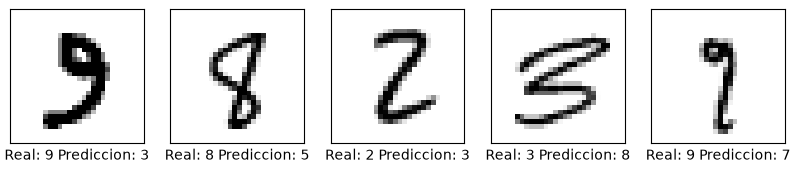

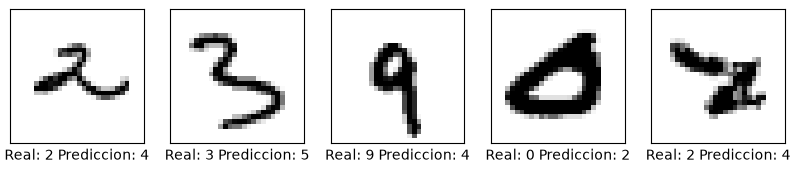

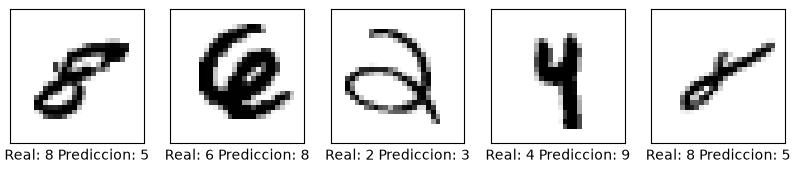

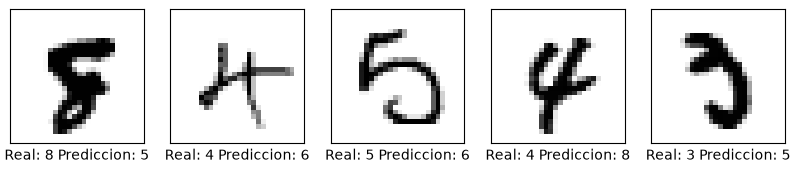

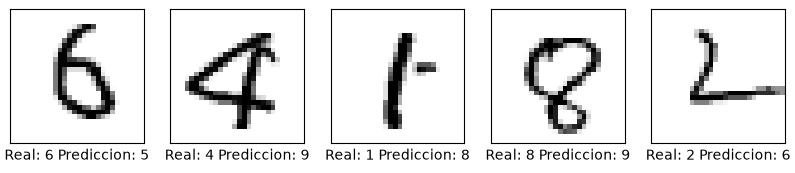

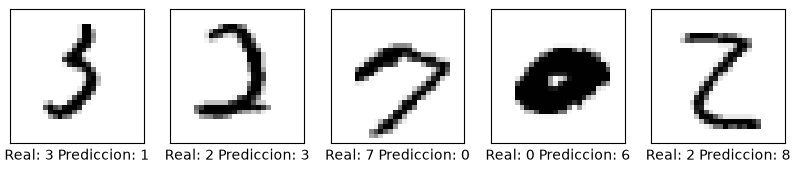

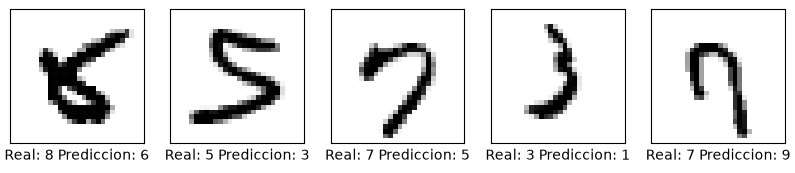

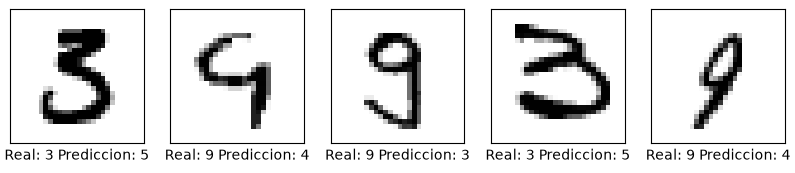

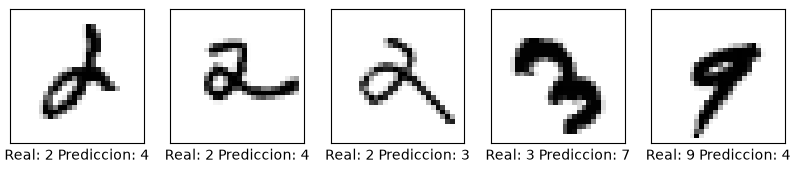

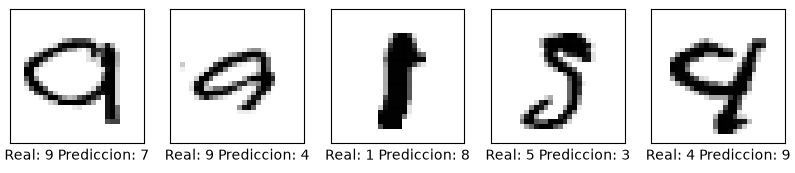

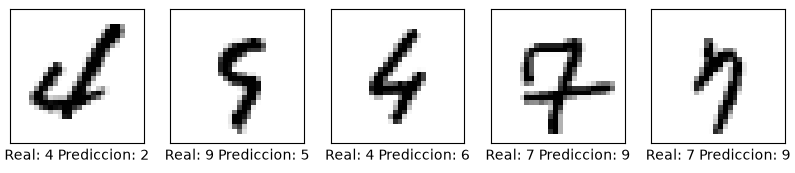

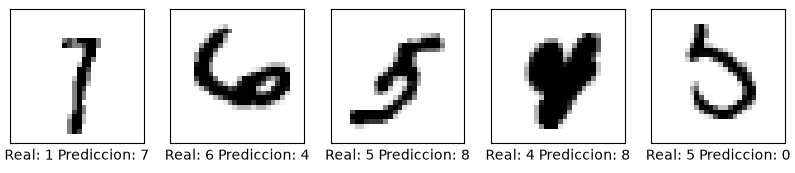

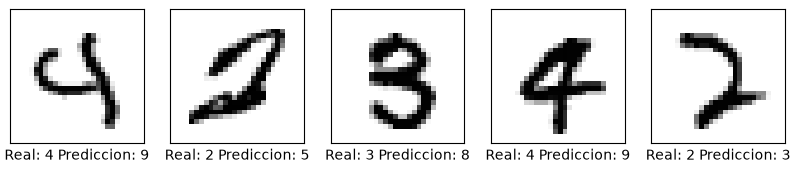

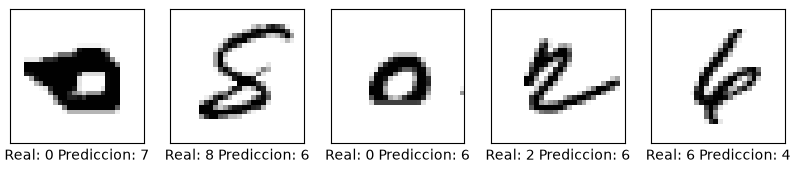

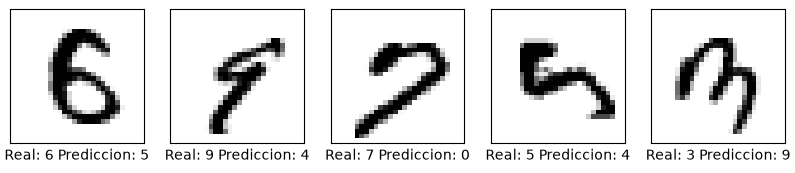

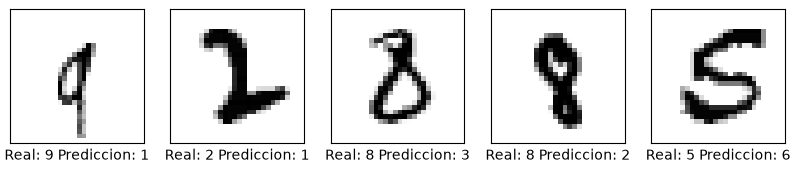

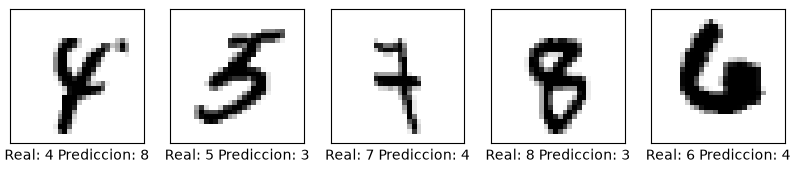

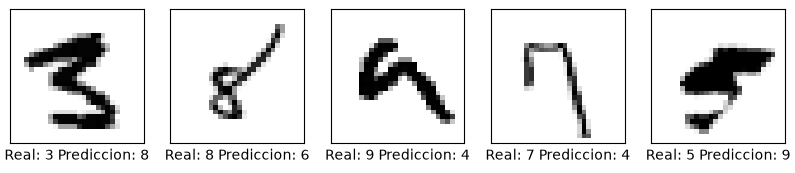

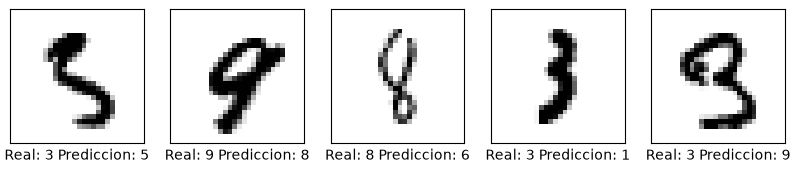

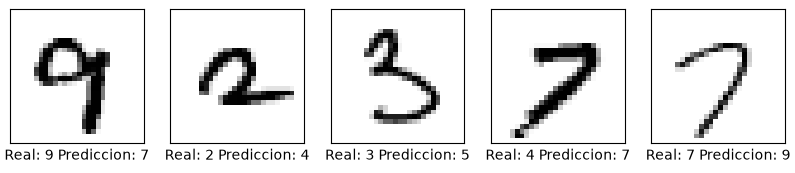

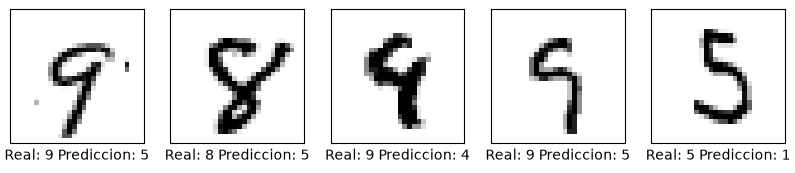

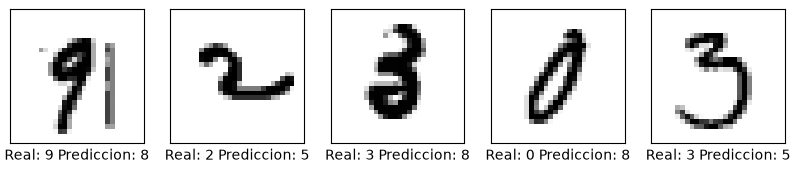

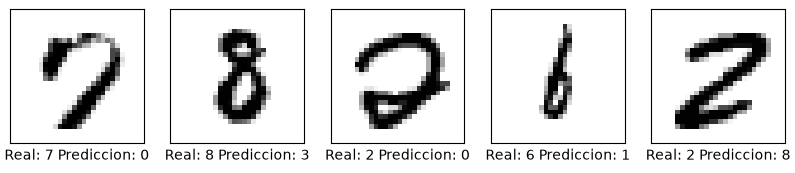

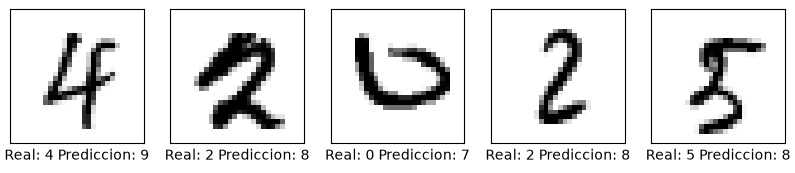

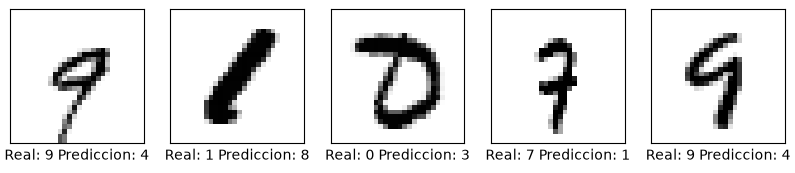

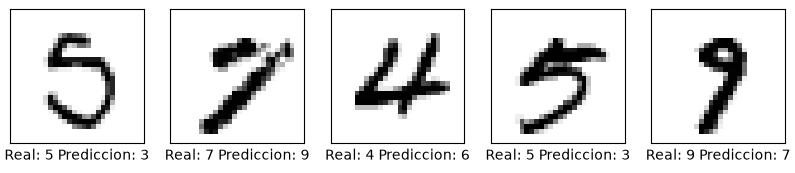

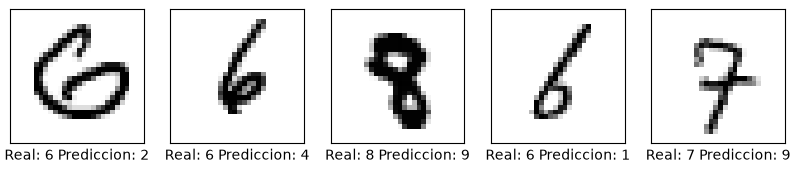

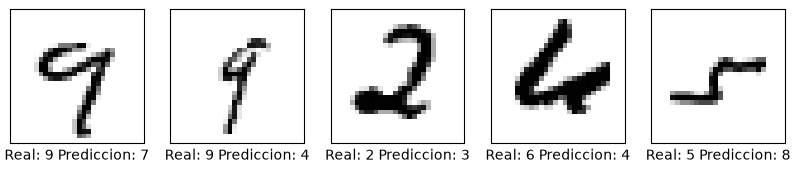

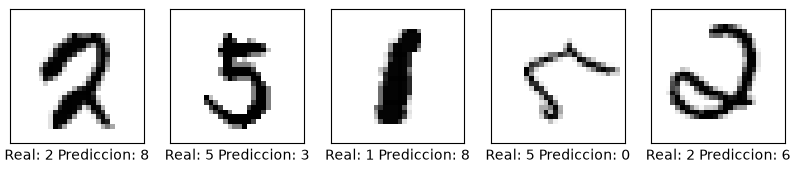

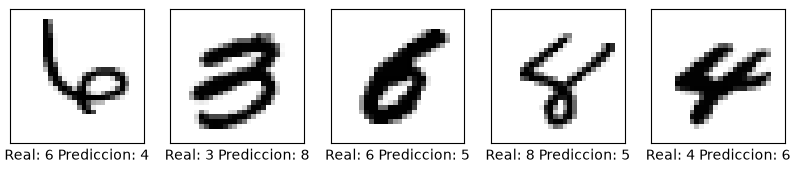

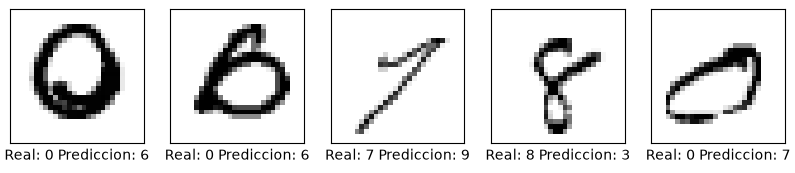

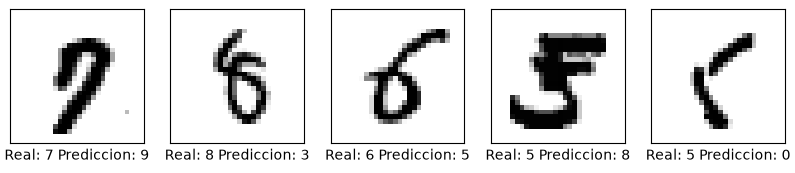

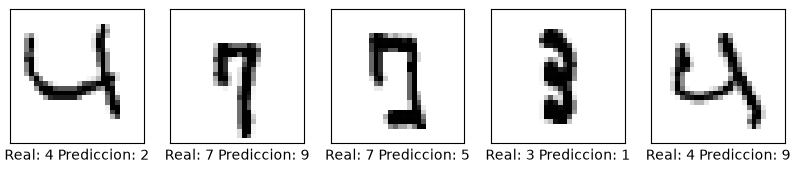

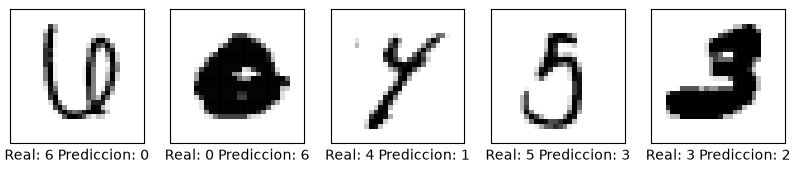

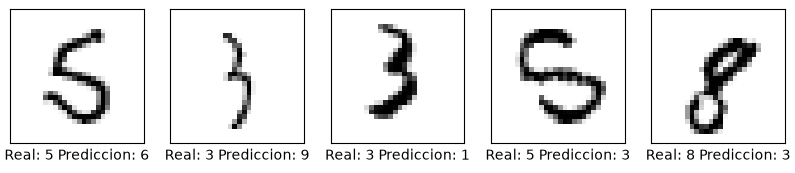

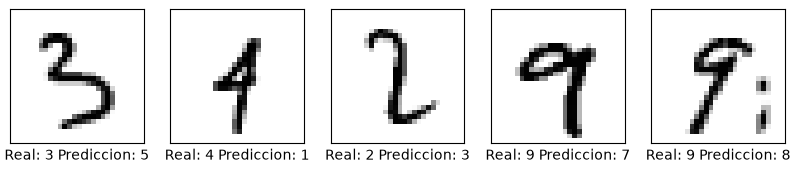

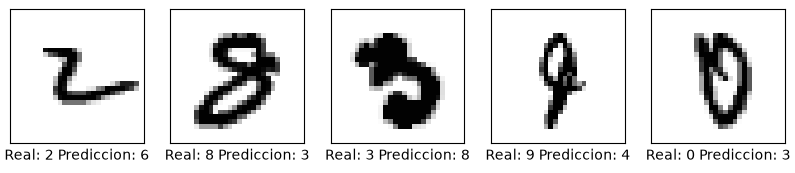

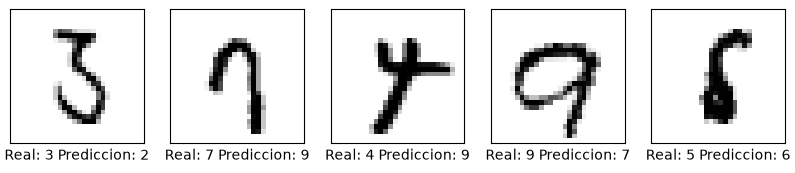

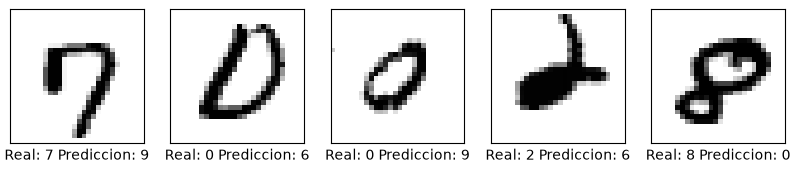

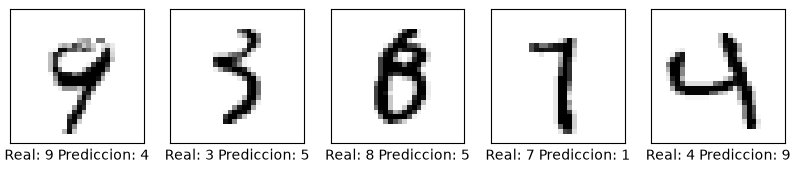

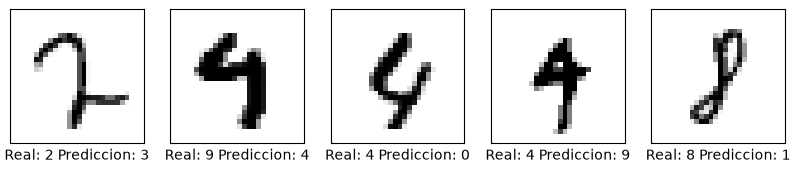

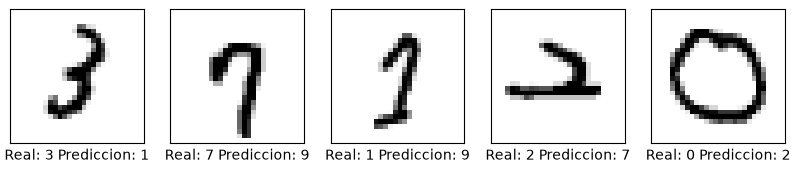

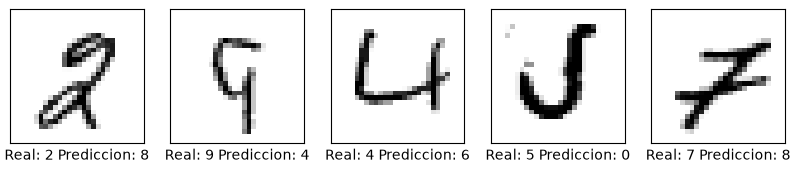

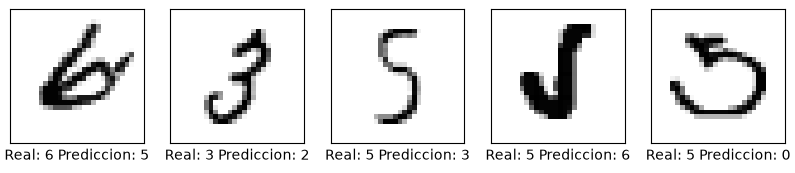

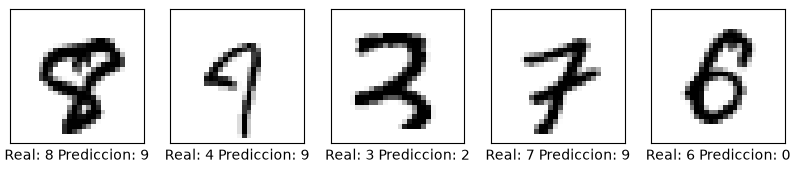

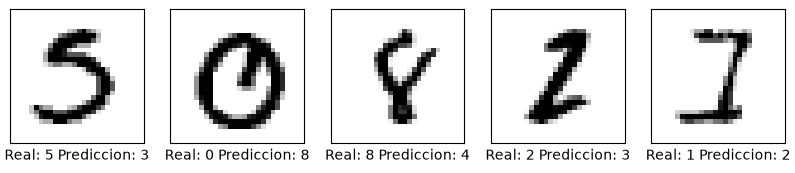

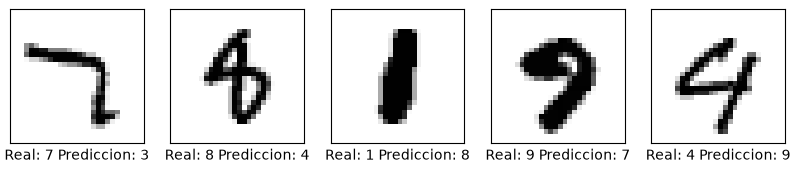

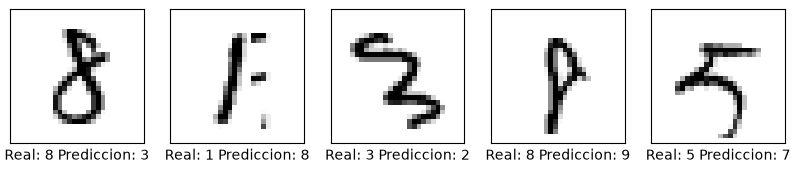

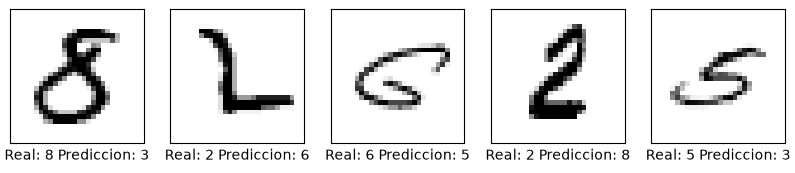

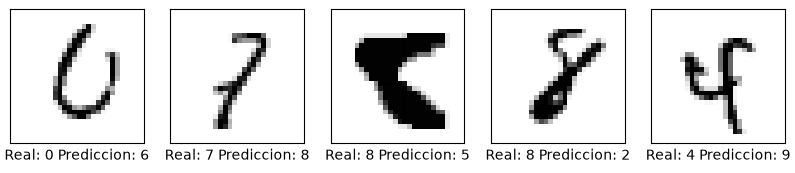

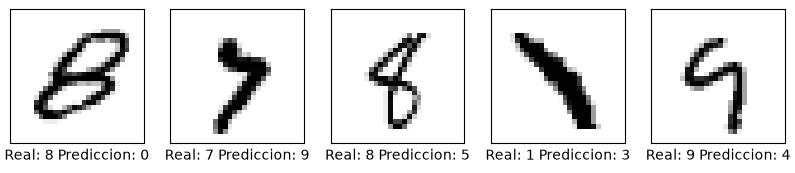

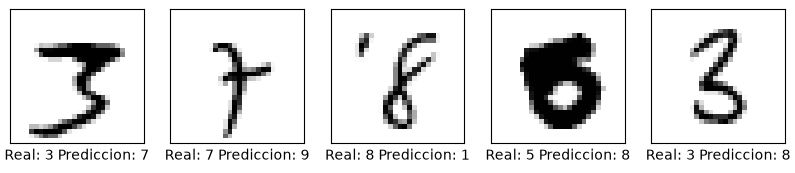

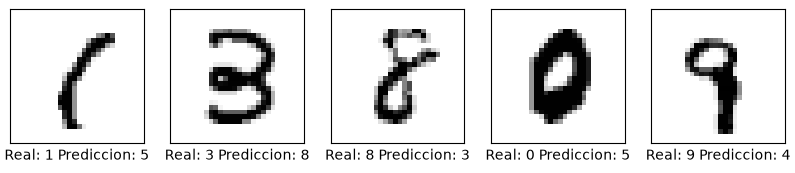

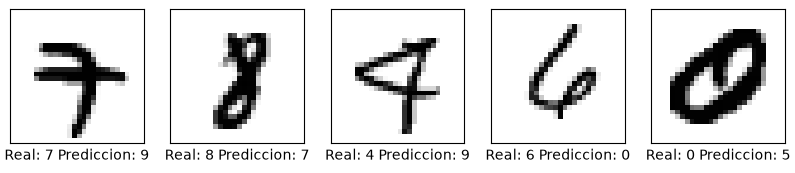

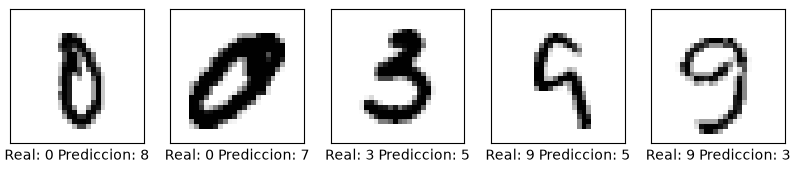

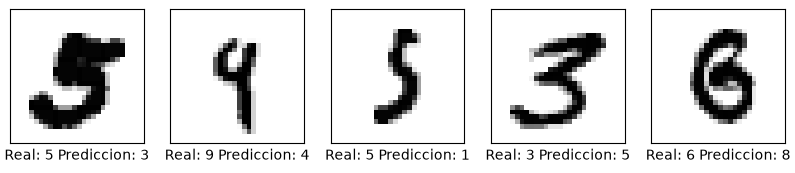

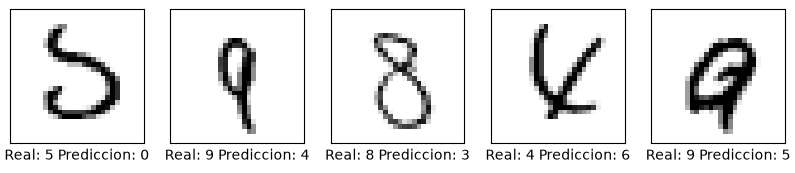

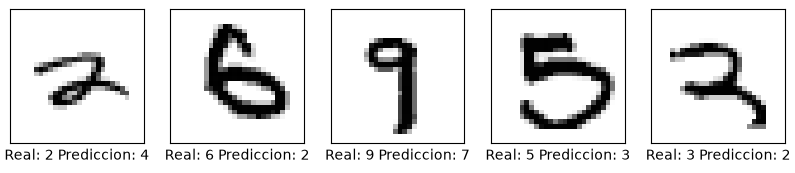

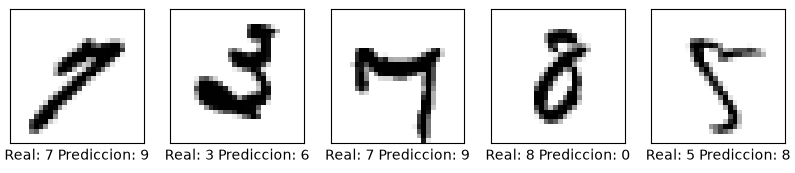

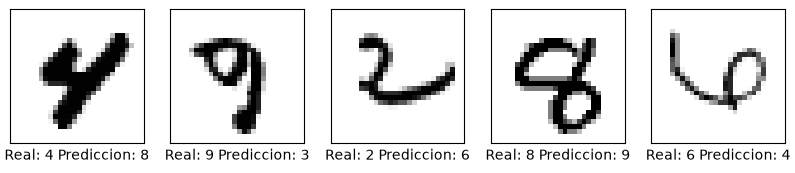

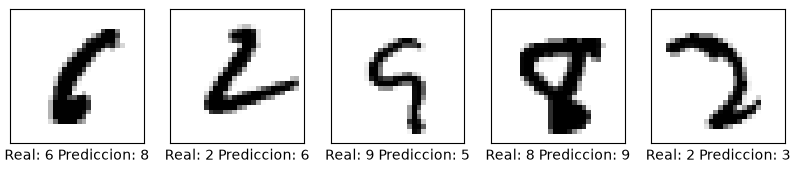

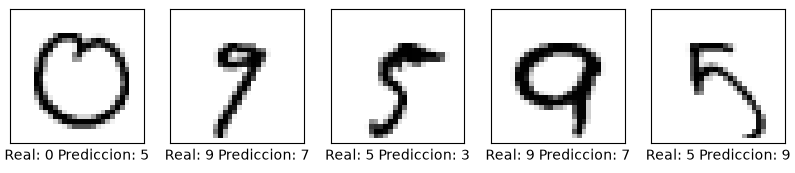

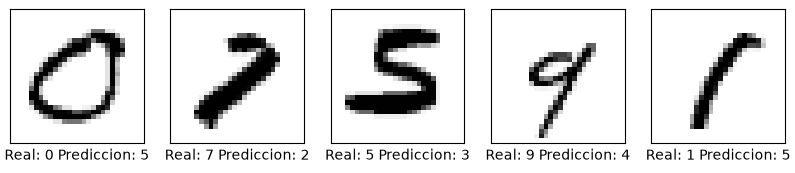

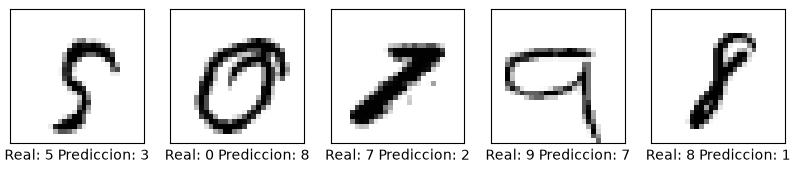

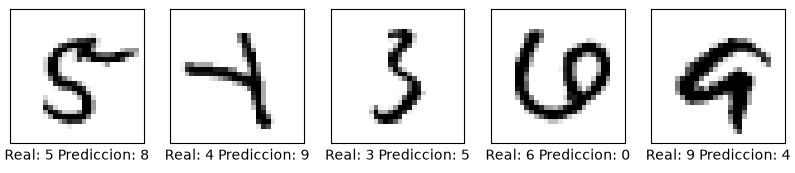

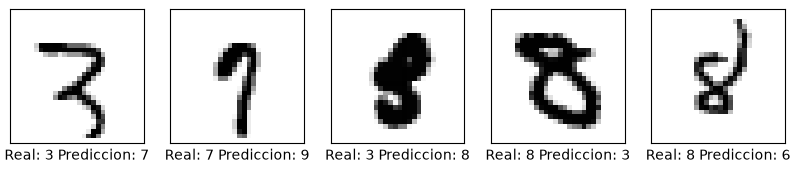

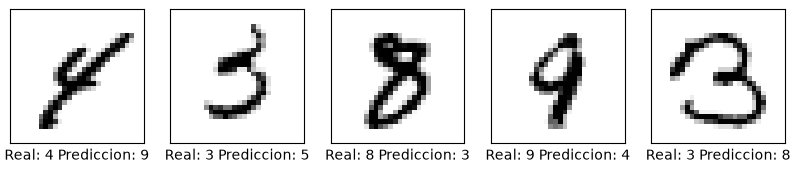

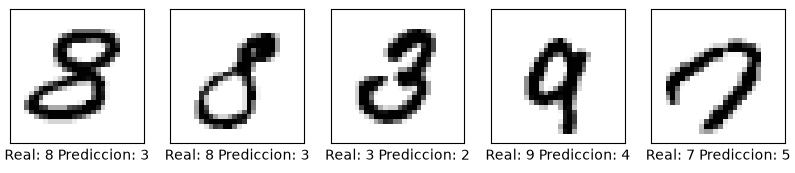

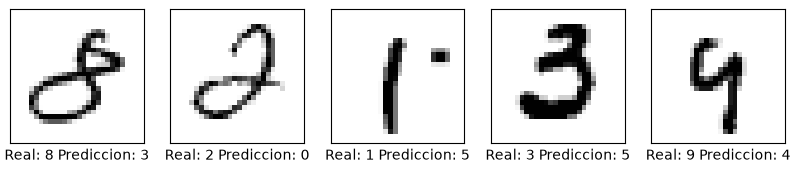

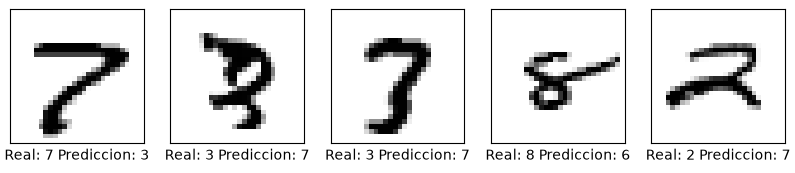

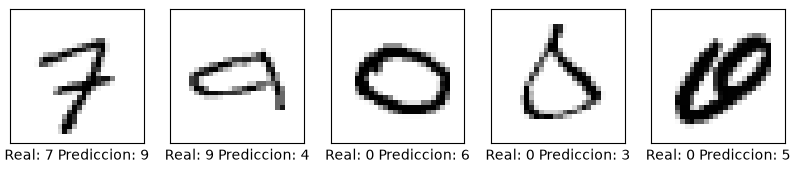

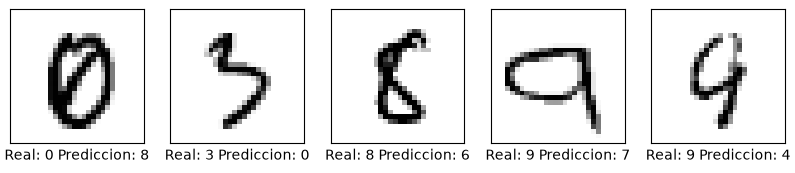

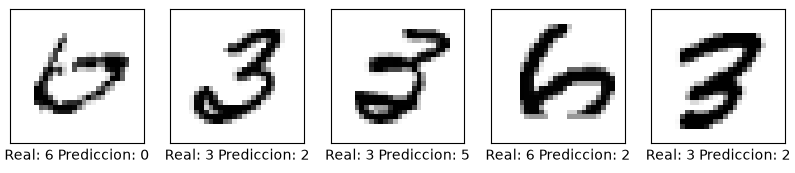

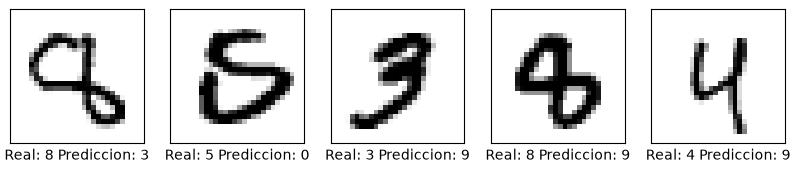

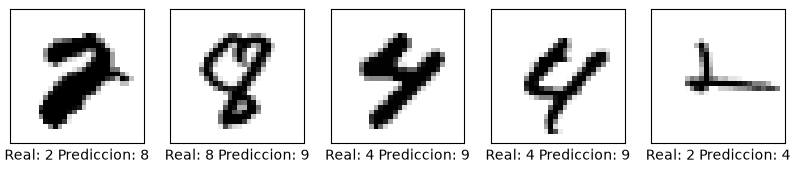

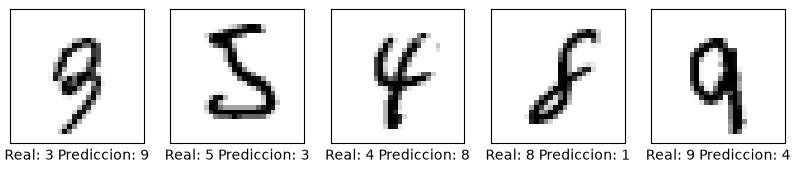

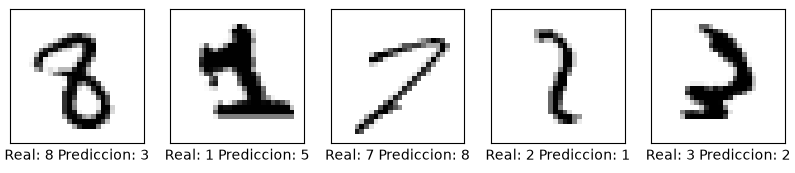

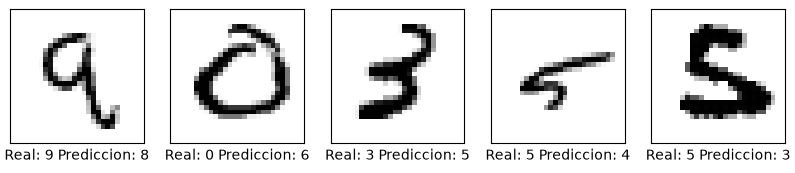

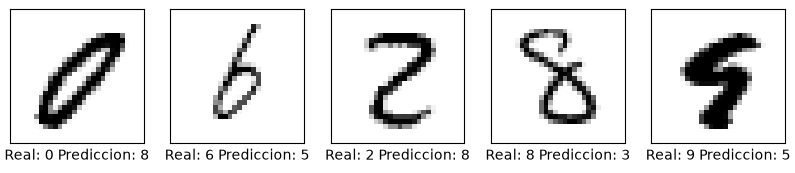

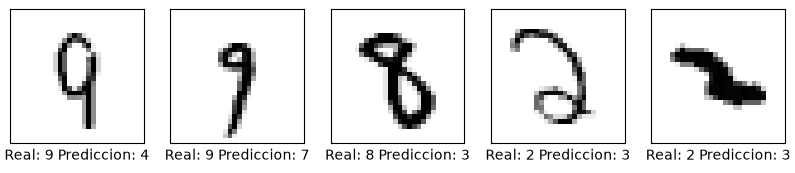

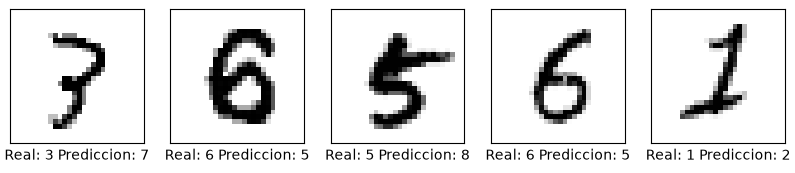

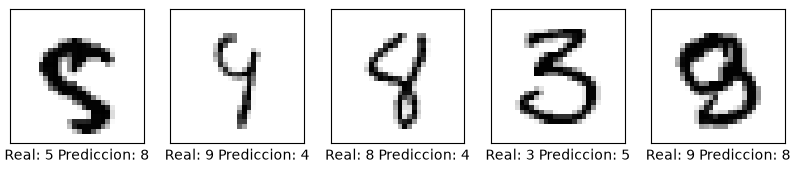

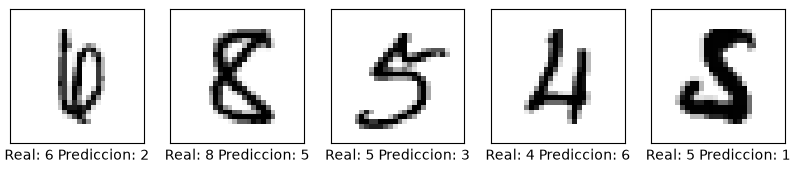

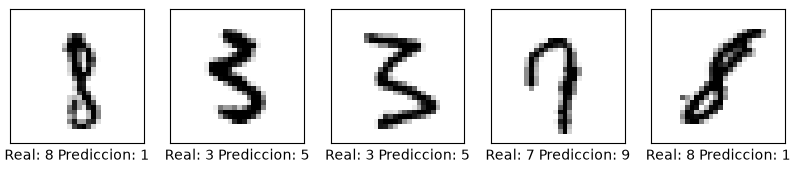

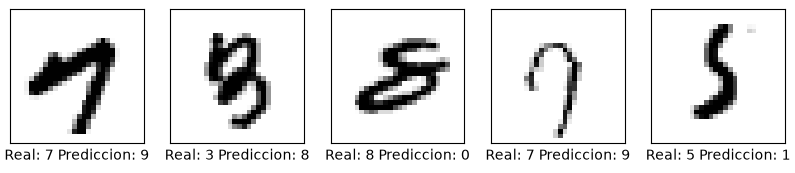

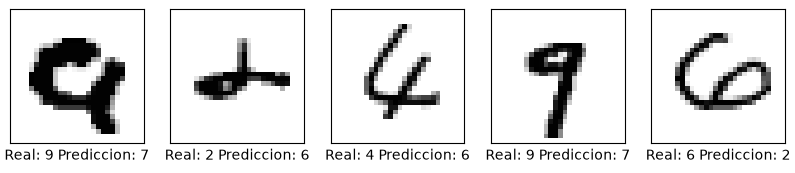

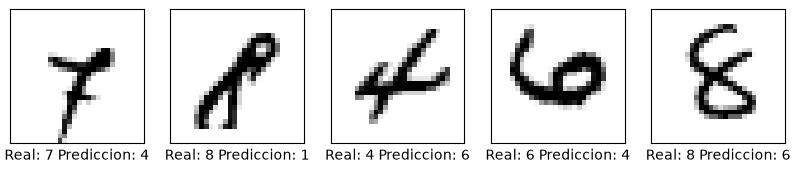

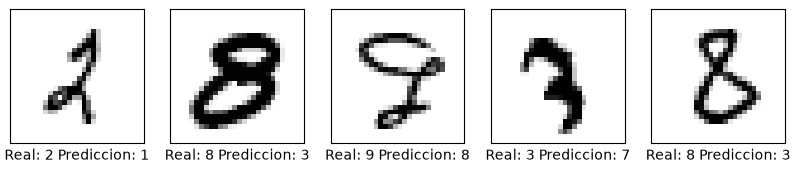

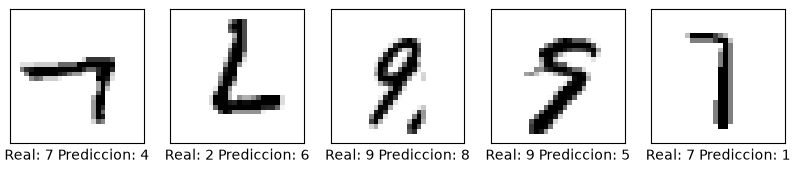

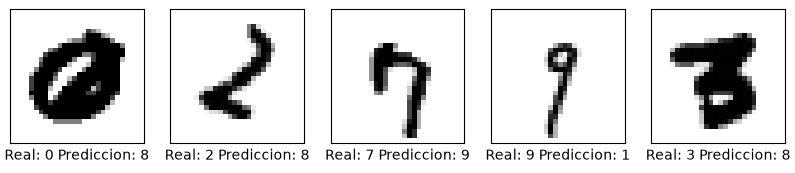

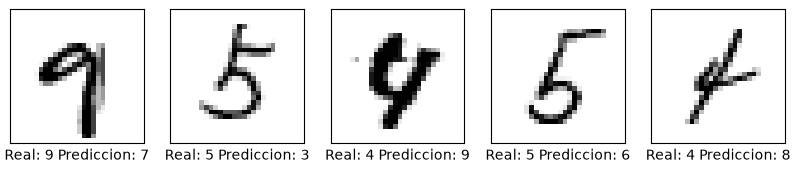

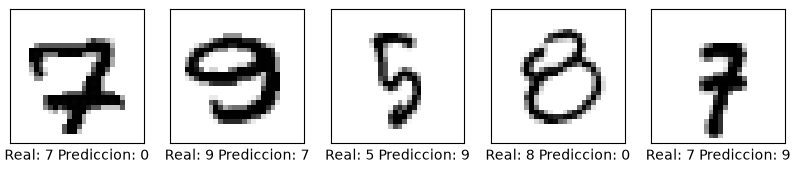

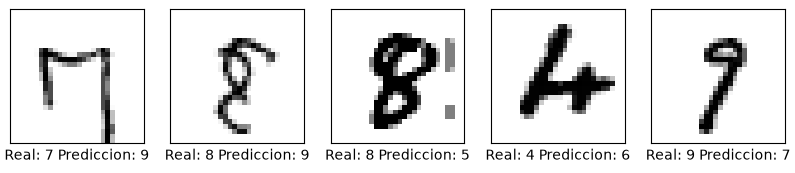

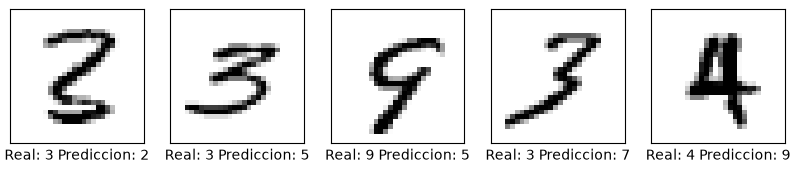

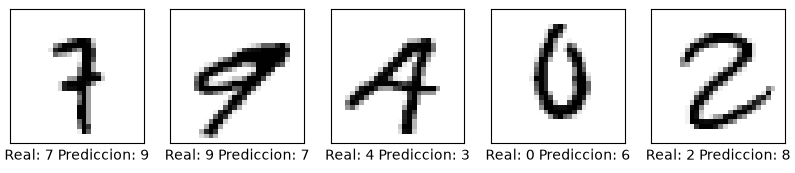

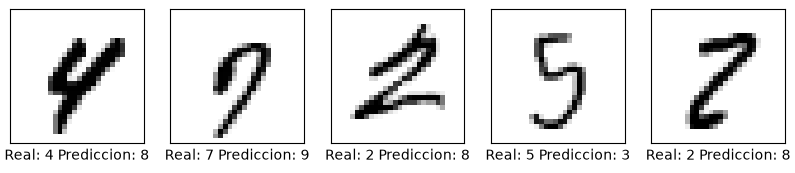

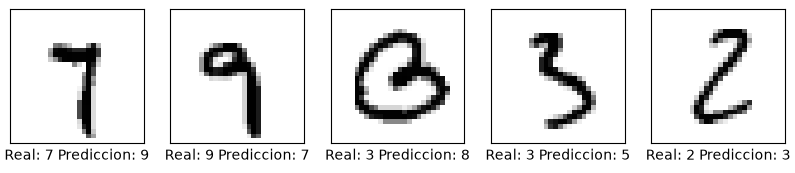

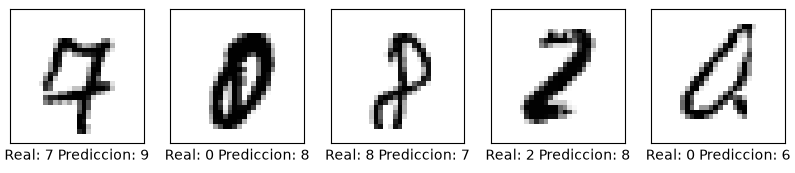

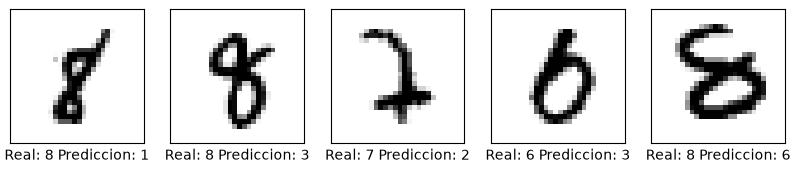

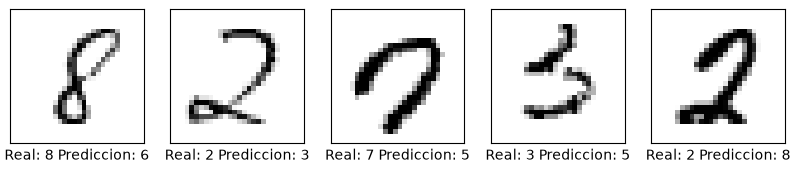

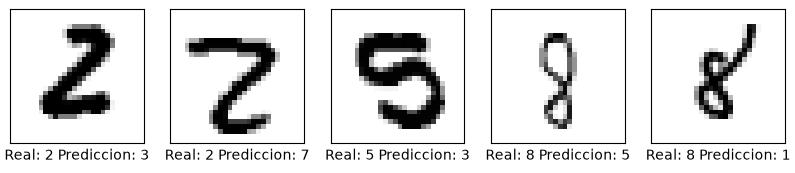

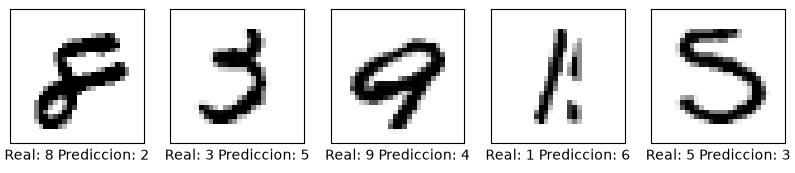

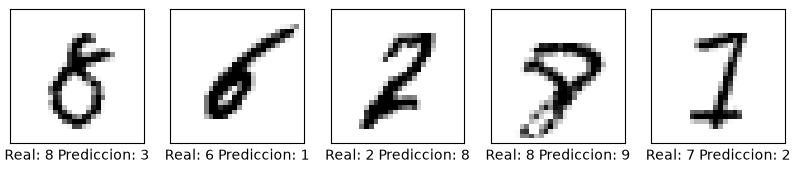

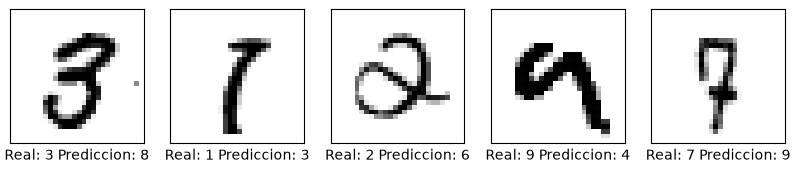

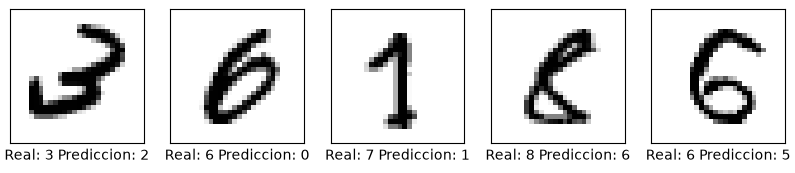

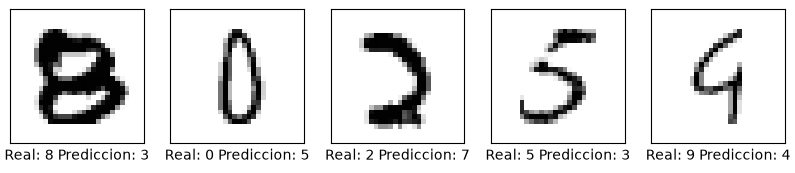

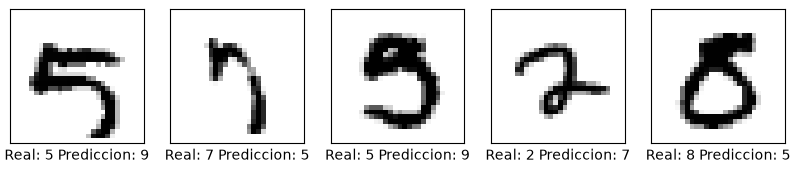

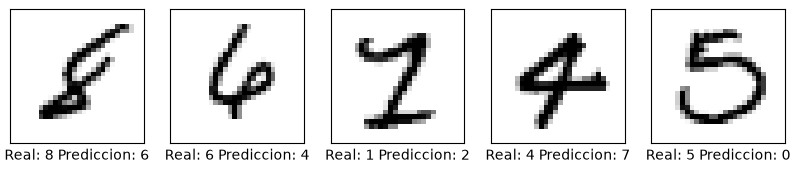

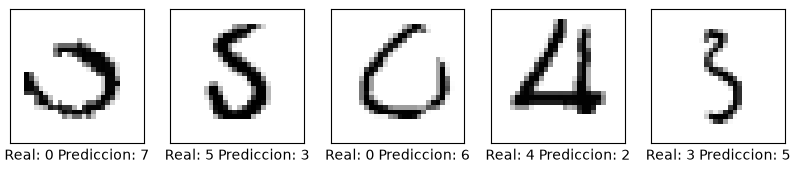

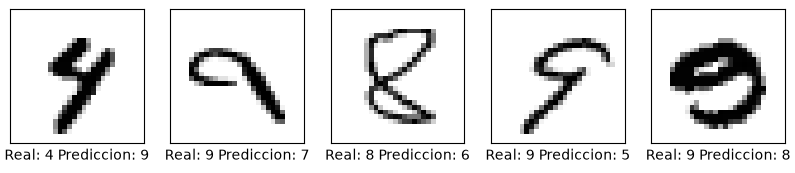

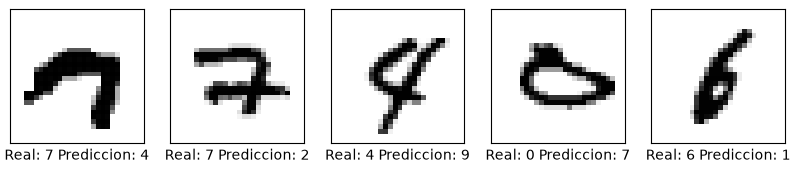

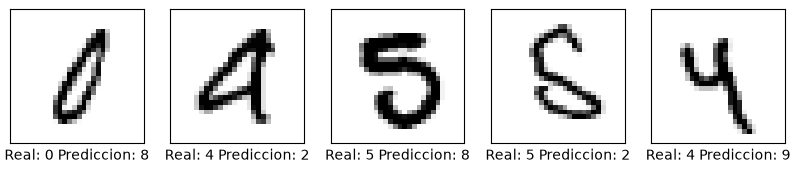

In [22]:
for j in range(round(errores.shape[0]/5)):
    plt.figure(figsize=(10,10))
    for i in range(5):
        plt.subplot(1,5,i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        number = errores[5*j+i].reshape(28,28)
        plt.imshow(number, cmap=plt.cm.binary)
        plt.xlabel("Real: {} Prediccion: {}".format
                   (real_labels[5*j+i],predicted_labels[5*j+i]))
    plt.show()

# Matriz de confusión

In [23]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test, y_hat)

array([[1217,    0,    2,    4,    1,    8,   13,    8,   10,    1],
       [   0, 1340,    3,    3,    0,    4,    1,    1,    7,    2],
       [   2,    5, 1179,   16,    7,    3,   11,    7,   22,    1],
       [   3,    7,   15, 1203,    0,   28,    2,    9,   18,    8],
       [   2,    2,    7,    2, 1163,    1,   12,    3,    7,   33],
       [   9,    4,    1,   26,    2,  995,    8,    1,   12,    7],
       [   7,    4,    6,    1,   10,   11, 1220,    0,    4,    0],
       [   5,    4,   10,    4,    8,    5,    0, 1284,    3,   34],
       [   6,   10,    3,   30,    3,   18,   15,    2, 1137,   13],
       [   1,    2,    0,    4,   44,   12,    0,   24,    8, 1180]])

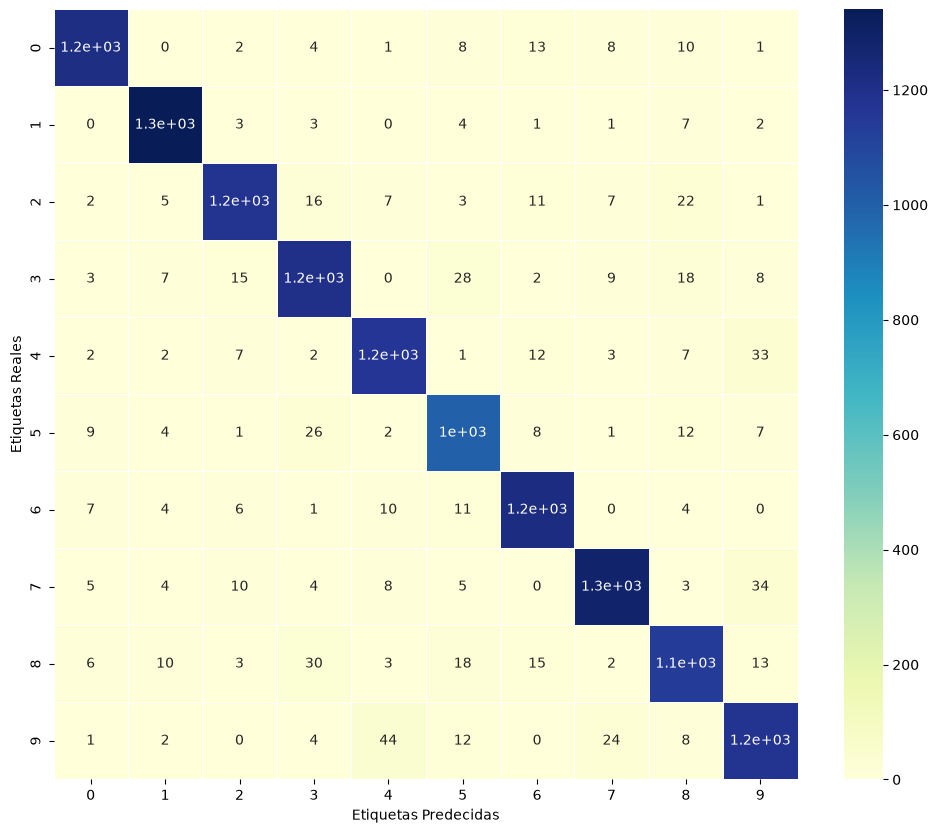

In [25]:
import seaborn as sns
plt.figure(figsize=(12,10))
sns.heatmap(confusion_matrix(y_test, y_hat), linewidth=0.5, annot=True, cmap="YlGnBu")
plt.ylabel("Etiquetas Reales")
plt.xlabel("Etiquetas Predecidas")
plt.show()

In [26]:
mod_confusion_matrix = confusion_matrix(y_test, y_hat)
for i in range(10):
    mod_confusion_matrix[i][i] = 0

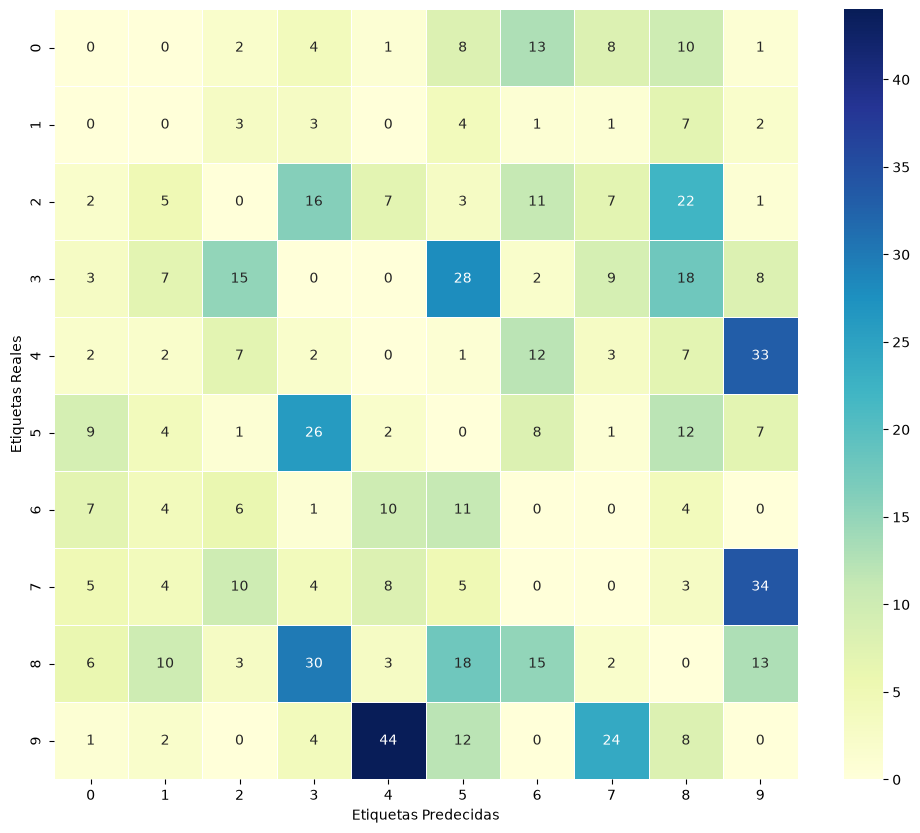

In [27]:
plt.figure(figsize=(12,10))
sns.heatmap(mod_confusion_matrix, linewidth=0.5, annot=True, cmap="YlGnBu")
plt.ylabel("Etiquetas Reales")
plt.xlabel("Etiquetas Predecidas")
plt.show()